In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=GoogLeNet_Weights.IMAGENET1K_V1`. You can also use `weights=GoogLeNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth
100%|██████████| 49.7M/49.7M [00:00<00:00, 84.5MB/s]


Epoch [1/100], Loss: 0.5088
Epoch [2/100], Loss: 0.2686
Epoch [3/100], Loss: 0.2056
Epoch [4/100], Loss: 0.1827
Epoch [5/100], Loss: 0.1708
Epoch [6/100], Loss: 0.1053
Epoch [7/100], Loss: 0.1076
Epoch [8/100], Loss: 0.1150
Epoch [9/100], Loss: 0.1062
Epoch [10/100], Loss: 0.0614
Epoch [11/100], Loss: 0.0359
Epoch [12/100], Loss: 0.0704
Epoch [13/100], Loss: 0.0574
Epoch [14/100], Loss: 0.1141
Epoch [15/100], Loss: 0.1917
Epoch [16/100], Loss: 0.1233
Epoch [17/100], Loss: 0.1295
Epoch [18/100], Loss: 0.1023
Epoch [19/100], Loss: 0.0470
Epoch [20/100], Loss: 0.0427
Epoch [21/100], Loss: 0.0866
Epoch [22/100], Loss: 0.0649
Epoch [23/100], Loss: 0.0779
Epoch [24/100], Loss: 0.0817
Epoch [25/100], Loss: 0.0270
Epoch [26/100], Loss: 0.0248
Epoch [27/100], Loss: 0.0317
Epoch [28/100], Loss: 0.0346
Epoch [29/100], Loss: 0.0745
Epoch [30/100], Loss: 0.0195
Epoch [31/100], Loss: 0.0157
Epoch [32/100], Loss: 0.0479
Epoch [33/100], Loss: 0.0815
Epoch [34/100], Loss: 0.0428
Epoch [35/100], Loss: 0

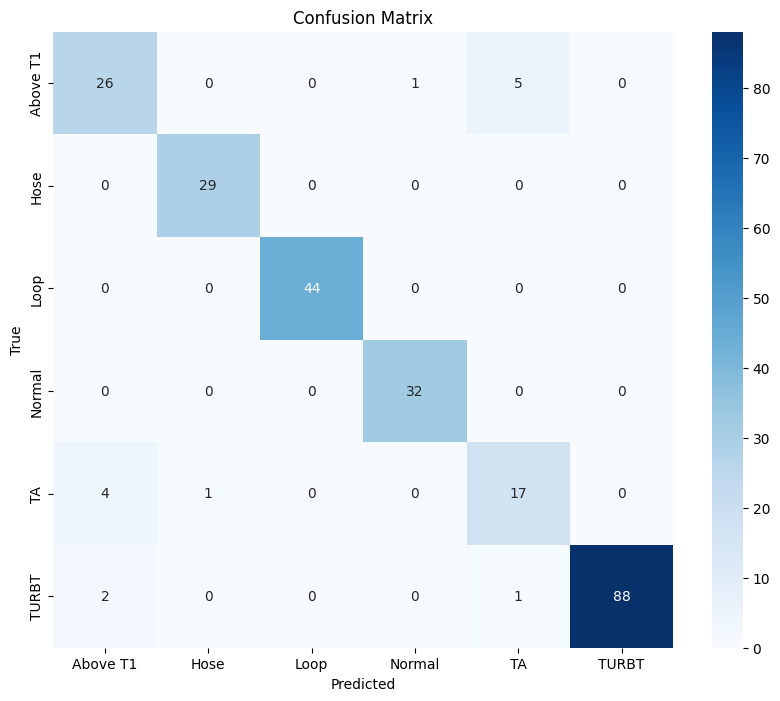

Classification Report:
              precision    recall  f1-score   support

    Above T1       0.81      0.81      0.81        32
        Hose       0.97      1.00      0.98        29
        Loop       1.00      1.00      1.00        44
      Normal       0.97      1.00      0.98        32
          TA       0.74      0.77      0.76        22
       TURBT       1.00      0.97      0.98        91

    accuracy                           0.94       250
   macro avg       0.91      0.93      0.92       250
weighted avg       0.95      0.94      0.94       250



In [ ]:
# Step 1: Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Step 2: Define transformations and load your dataset
# Define data transformations for train and test set
transform = transforms.Compose([
    transforms.Resize((224, 224)),   # Resize to 224x224 (GoogLeNet input size)
    transforms.ToTensor(),           # Convert images to PyTorch tensors
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])  # Normalize with ImageNet values
])

# Assuming you have a folder structure:
# - Train folder: data/train/ (with subfolders for each class)
# - Test folder: data/test/ (with subfolders for each class)

train_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/BLC/WLI_split/train', transform=transform)
test_dataset = datasets.ImageFolder(root='/content/drive/MyDrive/BLC/WLI_split/test', transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Step 3: Load GoogLeNet pre-trained model
model = torchvision.models.googlenet(pretrained=True)

# Modify the last layer to match the number of classes (6 in your case)
model.fc = nn.Linear(1024, 6)  # Replace the last fully connected layer

# Move model to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Step 4: Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Step 5: Train the model
num_epochs = 100

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward and optimize
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}')

# Step 6: Evaluate the model on test data
model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predicted.cpu().numpy())

# Step 7: Generate the Confusion Matrix and Classification Report
classes = train_dataset.classes  # Names of the classes

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=classes))


In [ ]:
# Install required packages
!pip install torch torchvision matplotlib scikit-learn
